<a href="https://colab.research.google.com/github/gayatrishekharcs/AI_LAB/blob/main/WEEK8_1BM24CS103_FORWARD_CHAINING.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

   FORWARD CHAINING INTERACTIVE INFERENCE SYSTEM  
Select a problem to execute:
1 -> Patient Influenza Test Problem (Fever, Sore Throat...)
2 -> American Crime FOL Problem (Robert, Weapons, Hostile...)
3 -> Abstract Logic Propositional Problem (A, B, L, M, P, Q)
Enter your choice (1, 2, or 3): 1

--- Running Problem 1: Patient Influenza Test ---
 -> [MATCH] R1 triggered! Inferred: InfectionSigns(P)
 -> [MATCH] R2 triggered! Inferred: TestInfluenza(P)

SUCCESS: Goal 'TestInfluenza(P)' has been proven!


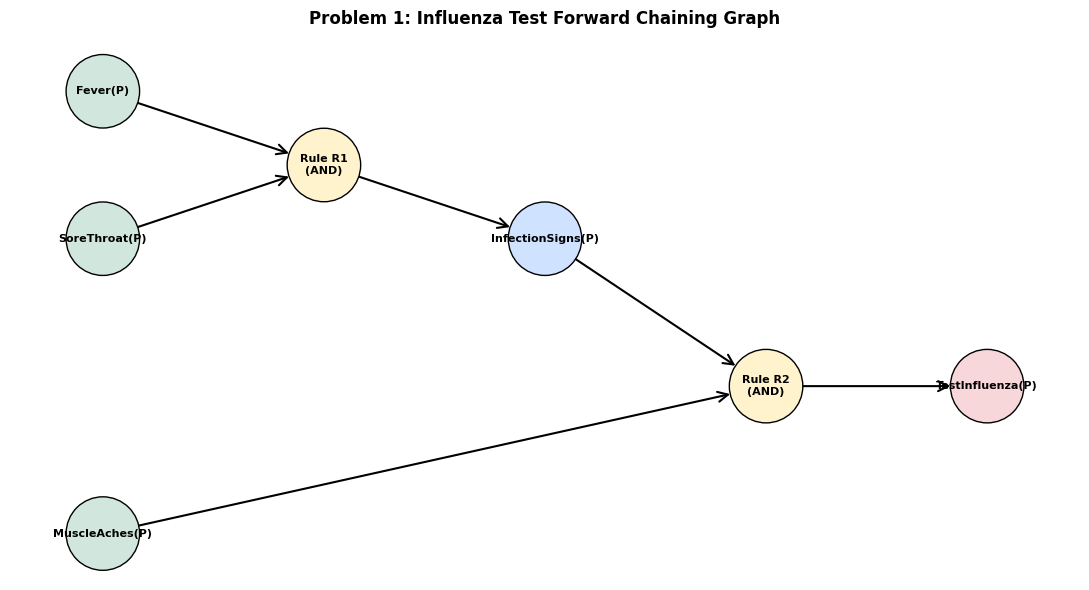

In [3]:
import matplotlib.pyplot as plt
import networkx as nx


def run_interactive_forward_chaining():
    print("==================================================")
    print("   FORWARD CHAINING INTERACTIVE INFERENCE SYSTEM  ")
    print("==================================================")
    print("Select a problem to execute:")
    print("1 -> Patient Influenza Test Problem (Fever, Sore Throat...)")
    print("2 -> American Crime FOL Problem (Robert, Weapons, Hostile...)")
    print("3 -> Abstract Logic Propositional Problem (A, B, L, M, P, Q)")
    print("==================================================")

    choice = input("Enter your choice (1, 2, or 3): ").strip()

    # ----------------------------------------------------
    # CONFIGURATION FOR PROBLEM 1: INFLUENZA TEST
    # ----------------------------------------------------
    if choice == "1":
        print("\n--- Running Problem 1: Patient Influenza Test ---")
        working_memory = {"Fever(P)", "SoreThroat(P)", "MuscleAches(P)"}
        goal = "TestInfluenza(P)"
        knowledge_base = [
            {
                "premises": ("Fever(P)", "SoreThroat(P)"),
                "conclusion": "InfectionSigns(P)",
                "label": "R1",
            },
            {
                "premises": ("InfectionSigns(P)", "MuscleAches(P)"),
                "conclusion": "TestInfluenza(P)",
                "label": "R2",
            },
        ]
        # Layout positions for graph rendering
        pos = {
            "Fever(P)": (0, 4),
            "SoreThroat(P)": (0, 3),
            "MuscleAches(P)": (0, 1),
            "Rule R1\n(AND)": (2, 3.5),
            "InfectionSigns(P)": (4, 3),
            "Rule R2\n(AND)": (6, 2),
            "TestInfluenza(P)": (8, 2),
        }
        title = "Problem 1: Influenza Test Forward Chaining Graph"

    # ----------------------------------------------------
    # CONFIGURATION FOR PROBLEM 2: AMERICAN CRIME
    # ----------------------------------------------------
    elif choice == "2":
        print("\n--- Running Problem 2: American Crime FOL ---")
        working_memory = {
            "American(Robert)",
            "Enemy(A, America)",
            "Owns(A, T1)",
            "Missile(T1)",
        }
        goal = "Criminal(Robert)"
        knowledge_base = [
            {
                "premises": ("Missile(T1)",),
                "conclusion": "Weapon(T1)",
                "label": "R1",
            },
            {
                "premises": ("Enemy(A, America)",),
                "conclusion": "Hostile(A)",
                "label": "R2",
            },
            {
                "premises": ("Missile(T1)", "Owns(A, T1)"),
                "conclusion": "Sells(Robert, T1, A)",
                "label": "R3",
            },
            {
                "premises": (
                    "American(Robert)",
                    "Weapon(T1)",
                    "Sells(Robert, T1, A)",
                    "Hostile(A)",
                ),
                "conclusion": "Criminal(Robert)",
                "label": "R4",
            },
        ]
        pos = {
            "American(Robert)": (1, 5),
            "Missile(T1)": (3, 5),
            "Owns(A, T1)": (5, 5),
            "Enemy(A, America)": (8, 5),
            "Rule R1\n(AND)": (2.2, 4),
            "Rule R2\n(AND)": (8, 4),
            "Rule R3\n(AND)": (4.2, 4),
            "Weapon(T1)": (2.2, 3),
            "Sells(Robert, T1, A)": (4.2, 3),
            "Hostile(A)": (8, 3),
            "Rule R4\n(AND)": (4.5, 1.8),
            "Criminal(Robert)": (4.5, 0.5),
        }
        title = "Problem 2: American Crime Forward Chaining Graph"

    # ----------------------------------------------------
    # CONFIGURATION FOR PROBLEM 3: ABSTRACT SYMBOL LOGIC
    # ----------------------------------------------------
    elif choice == "3":
        print("\n--- Running Problem 3: Abstract Propositional Logic ---")
        working_memory = {"A", "B"}
        goal = "Q"
        knowledge_base = [
            {"premises": ("A", "B"), "conclusion": "L", "label": "R5"},
            {"premises": ("B", "L"), "conclusion": "M", "label": "R3"},
            {"premises": ("L", "M"), "conclusion": "P", "label": "R2"},
            {"premises": ("P",), "conclusion": "Q", "label": "R1"},
        ]
        pos = {
            "A": (1, 5),
            "B": (5, 5),
            "Rule R5\n(AND)": (3, 4.2),
            "L": (3, 3.2),
            "Rule R3\n(AND)": (4.5, 2.5),
            "M": (5, 1.5),
            "Rule R2\n(AND)": (2.5, 1.5),
            "P": (1, 1.5),
            "Rule R1\n(AND)": (1, 2.8),
            "Q": (1, 4.0),
        }
        title = "Problem 3: Abstract Propositional Forward Chaining Graph"

    else:
        print("Invalid choice! Exiting program.")
        return

    # Initialize standard networkx directed graph container
    G = nx.DiGraph()

    # Seed the graph framework with base fact states
    for fact in working_memory:
        G.add_node(fact, type="fact", status="initial")

    # ----------------------------------------------------
    # ENGINE CORNER: EXECUTE THE INFERENCE ENGINE
    # ----------------------------------------------------
    changed = True
    while changed and goal not in working_memory:
        changed = False
        for rule in knowledge_base:
            premises = rule["premises"]
            conclusion = rule["conclusion"]
            rule_id = rule["label"]

            if conclusion not in working_memory:
                if all(p in working_memory for p in premises):
                    working_memory.add(conclusion)
                    changed = True

                    # Generate visual operational link node
                    rule_node = f"Rule {rule_id}\n(AND)"
                    G.add_node(rule_node, type="rule")

                    # Connect structural layout lines
                    for p in premises:
                        G.add_edge(p, rule_node)
                    G.add_node(
                        conclusion,
                        type="fact",
                        status="goal" if conclusion == goal else "derived",
                    )
                    G.add_edge(rule_node, conclusion)

                    print(
                        f" -> [MATCH] {rule_id} triggered! Inferred: {conclusion}"
                    )

    # Check execution finish status
    if goal in working_memory:
        print(f"\nSUCCESS: Goal '{goal}' has been proven!")
    else:
        print(f"\nFAILURE: Goal '{goal}' cannot be reached.")

    # ----------------------------------------------------
    # PLOTTING CORNER: DRAW GRAPH VIA MATPLOTLIB
    # ----------------------------------------------------
    plt.figure(figsize=(11, 6))

    node_colors = []
    for node in G.nodes():
        node_attr = G.nodes[node]
        if node_attr.get("type") == "rule":
            node_colors.append("#fff3cd")  # Yellow logic junction boxes
        elif node_attr.get("status") == "initial":
            node_colors.append("#d1e7dd")  # Green initial user parameters
        elif node_attr.get("status") == "goal":
            node_colors.append("#f8d7da")  # Red final targeted proof element
        else:
            node_colors.append("#cfe2ff")  # Blue runtime derived items

    nx.draw_networkx_nodes(
        G, pos, node_size=2800, node_color=node_colors, edgecolors="black"
    )
    nx.draw_networkx_labels(G, pos, font_size=8, font_weight="bold")
    nx.draw_networkx_edges(
        G,
        pos,
        arrowstyle="->",
        arrowsize=18,
        edge_color="black",
        width=1.5,
        node_size=2800,
    )

    plt.title(title, weight="bold", fontsize=12, pad=15)
    plt.axis("off")
    plt.tight_layout()
    plt.show()


if __name__ == "__main__":
    run_interactive_forward_chaining()


      UNIVERSAL FORWARD CHAINING GRAPH SYSTEM     
Step 1: Enter your initial true facts separated by commas.
Example: Fever, SoreThroat, MuscleAches
Initial Facts: A,B

Step 2: Enter your production rules one by one.
Format: Premise1 & Premise2 -> Conclusion
Example: Fever & SoreThroat -> InfectionSigns
Type 'DONE' or leave line blank and press Enter when finished.
Rule 1: A & B -> L
Rule 2: B & L -> M
Rule 3: L & M -> P
Rule 4: P -> Q
Rule 5: DONE

Step 3: (Optional) Enter a specific goal target to prove.
Leave blank to run the algorithm until no more facts can be inferred.
Goal Target: Q

--- Inference Execution Log ---
[Iteration 1] Fired R1: (A & B -> L) -> New Fact Added: L
[Iteration 2] Fired R2: (B & L -> M) -> New Fact Added: M
[Iteration 3] Fired R3: (L & M -> P) -> New Fact Added: P
[Iteration 4] Fired R4: (P -> Q) -> New Fact Added: Q

[SUCCESS] Targeted goal 'Q' has been verified!


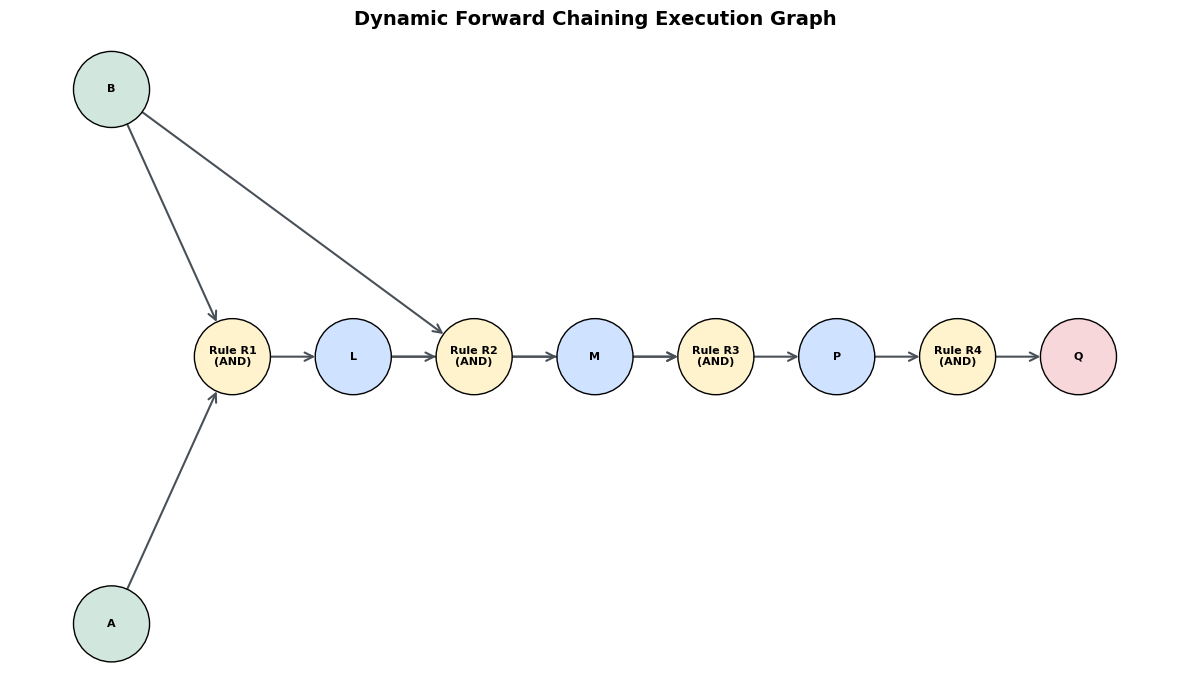

In [4]:
import matplotlib.pyplot as plt
import networkx as nx


def parse_inputs():
    print("==================================================")
    print("      UNIVERSAL FORWARD CHAINING GRAPH SYSTEM     ")
    print("==================================================")

    # 1. Get Initial Facts
    print("Step 1: Enter your initial true facts separated by commas.")
    print("Example: Fever, SoreThroat, MuscleAches")
    facts_input = input("Initial Facts: ").strip()
    working_memory = set(
        [f.strip() for f in facts_input.split(",") if f.strip()]
    )

    # 2. Get Rules
    print("\nStep 2: Enter your production rules one by one.")
    print("Format: Premise1 & Premise2 -> Conclusion")
    print("Example: Fever & SoreThroat -> InfectionSigns")
    print("Type 'DONE' or leave line blank and press Enter when finished.")

    knowledge_base = []
    rule_counter = 1
    while True:
        rule_input = input(f"Rule {rule_counter}: ").strip()
        if rule_input.upper() == "DONE" or not rule_input:
            break

        if "->" in rule_input:
            left, right = rule_input.split("->")
            premises = tuple([p.strip() for p in left.split("&") if p.strip()])
            conclusion = right.strip()
            if premises and conclusion:
                knowledge_base.append(
                    {
                        "premises": premises,
                        "conclusion": conclusion,
                        "id": f"R{rule_counter}",
                        "raw": rule_input,
                    }
                )
                rule_counter += 1
        else:
            print(
                "Invalid format. Please use '&' for AND conditions and '->' for implication."
            )

    # 3. Get Optional Goal Target
    print("\nStep 3: (Optional) Enter a specific goal target to prove.")
    print("Leave blank to run the algorithm until no more facts can be inferred.")
    goal = input("Goal Target: ").strip()

    return working_memory, knowledge_base, goal if goal else None


def execute_forward_chaining(working_memory, knowledge_base, goal):
    G = nx.DiGraph()

    # Track layers for visualization (Initial facts = Layer 0)
    node_layers = {}
    for fact in working_memory:
        G.add_node(fact, type="fact", status="initial", layer=0)
        node_layers[fact] = 0

    print("\n--- Inference Execution Log ---")
    changed = True
    iteration = 1

    while changed:
        changed = False
        # Create a snapshot copy of current rules to iterate safely
        triggered_this_round = []

        for rule in knowledge_base:
            premises = rule["premises"]
            conclusion = rule["conclusion"]
            rule_id = rule["id"]

            if conclusion not in working_memory:
                # Check if all elements of the rule condition are satisfied
                if all(p in working_memory for p in premises):
                    triggered_this_round.append((rule, premises, conclusion))

        # Apply inferences safely after evaluating current snapshot
        for rule, premises, conclusion in triggered_this_round:
            working_memory.add(conclusion)
            changed = True

            # Determine visual layer based on the deepest premise dependency
            max_premise_layer = max(node_layers.get(p, 0) for p in premises)
            rule_layer = max_premise_layer + 1
            conclusion_layer = rule_layer + 1

            rule_node = f"Rule {rule['id']}\n(AND)"
            G.add_node(rule_node, type="rule", layer=rule_layer)
            node_layers[rule_node] = rule_layer

            status_type = "goal" if conclusion == goal else "derived"
            G.add_node(
                conclusion, type="fact", status=status_type, layer=conclusion_layer
            )
            node_layers[conclusion] = conclusion_layer

            # Draw visual logic lines
            for p in premises:
                if not G.has_node(p):
                    G.add_node(p, type="fact", status="initial", layer=0)
                G.add_edge(p, rule_node)
            G.add_edge(rule_node, conclusion)

            print(
                f"[Iteration {iteration}] Fired {rule['id']}: ({rule['raw']}) -> New Fact Added: {conclusion}"
            )

        if goal and goal in working_memory:
            print(f"\n[SUCCESS] Targeted goal '{goal}' has been verified!")
            break

        iteration += 1

    if goal and goal not in working_memory:
        print(f"\n[HALT] Inference completed. Goal '{goal}' could not be proven.")

    return G


def plot_graph(G, goal):
    if len(G.nodes) == 0:
        print("No inferences were made. The graph is empty.")
        return

    plt.figure(figsize=(12, 7))

    # Compute a clean layout grid systematically separating layers
    pos = nx.multipartite_layout(G, subset_key="layer", align="vertical")

    node_colors = []
    for node in G.nodes():
        node_attr = G.nodes[node]
        if node_attr.get("type") == "rule":
            node_colors.append("#fff3cd")  # Yellow evaluation nodes
        elif node_attr.get("status") == "initial":
            node_colors.append("#d1e7dd")  # Green initial user parameters
        elif node_attr.get("status") == "goal":
            node_colors.append("#f8d7da")  # Red successfully checked goal
        else:
            node_colors.append("#cfe2ff")  # Blue intermediate derived assets

    # Render layout shapes
    nx.draw_networkx_nodes(
        G, pos, node_size=3000, node_color=node_colors, edgecolors="black"
    )
    nx.draw_networkx_labels(
        G, pos, font_size=8, font_weight="bold", font_family="sans-serif"
    )
    nx.draw_networkx_edges(
        G,
        pos,
        arrowstyle="->",
        arrowsize=15,
        edge_color="#495057",
        width=1.5,
        node_size=3000,
    )

    plt.title(
        "Dynamic Forward Chaining Execution Graph", weight="bold", fontsize=14
    )
    plt.axis("off")
    plt.tight_layout()
    plt.show()


if __name__ == "__main__":
    initial_facts, rules_list, target_goal = parse_inputs()
    inference_graph = execute_forward_chaining(
        initial_facts, rules_list, target_goal
    )
    plot_graph(inference_graph, target_goal)
